# Computational Analysis of the Sri Caitanya-caritamrta

Character interaction networks, sentiment, emotion and topics across the 62
chapters of the Caitanya-caritamrta, following the design of the Ramcharitmanas
study.

**Corpus.** The translation sections only - Krsnadasa Kaviraja's 16th-century
text, excluding Bhaktivedanta Swami Prabhupada's 20th-century purports.

Every figure is written to `results/figures/` at 300 dpi for the paper.

## 0. Setup

`USE_CACHE = True` reuses a previous character-recognition pass, which is the
slow step (a few minutes over 400k words).

In [1]:
%matplotlib inline

import json, os, statistics
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tokenize import sent_tokenize, word_tokenize

import chapters as chapters_mod
import common
import narrative

USE_CACHE = True
FIGURES = narrative.FIGURES
os.makedirs(FIGURES, exist_ok=True)

# Publication defaults: readable at single-column width, 300 dpi on save.
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
})

common.ensure_nltk()
analyzer = SentimentIntensityAnalyzer()
STOP = set(stopwords.words('english'))
LILA_COLOURS = {'Adi': '#4C72B0', 'Madhya': '#DD8452', 'Antya': '#55A868'}
print('setup complete')

setup complete


## 0b. Method

The pipeline, mirroring the Ramcharitmanas study's methodology figure.

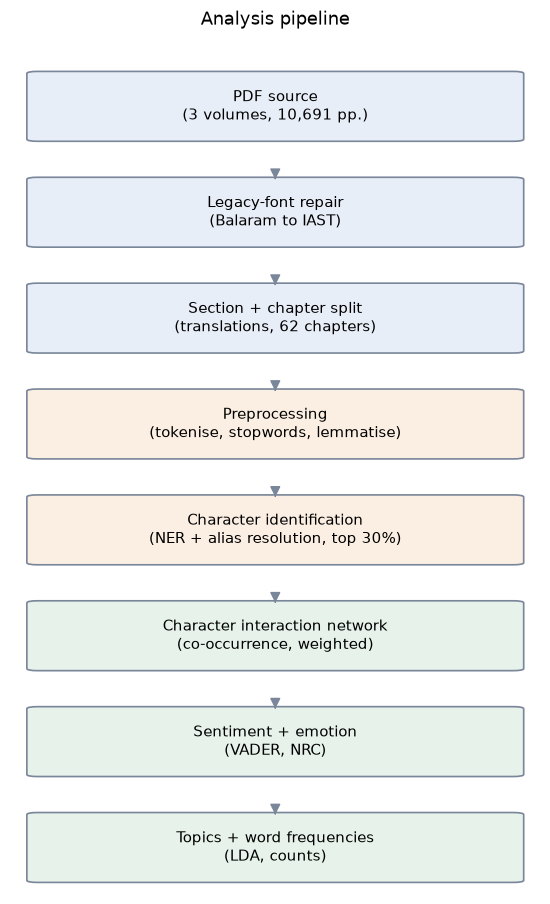

In [2]:
# FIGURE A - methodology flowchart.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

steps = [
    ('PDF source\n(3 volumes, 10,691 pp.)', '#E8EEF7'),
    ('Legacy-font repair\n(Balaram to IAST)', '#E8EEF7'),
    ('Section + chapter split\n(translations, 62 chapters)', '#E8EEF7'),
    ('Preprocessing\n(tokenise, stopwords, lemmatise)', '#FBEFE3'),
    ('Character identification\n(NER + alias resolution, top 30%)', '#FBEFE3'),
    ('Character interaction network\n(co-occurrence, weighted)', '#E6F2EA'),
    ('Sentiment + emotion\n(VADER, NRC)', '#E6F2EA'),
    ('Topics + word frequencies\n(LDA, counts)', '#E6F2EA'),
]

fig, ax = plt.subplots(figsize=(6.2, 10))
for i, (label, colour) in enumerate(steps):
    y = len(steps) - i - 1
    ax.add_patch(FancyBboxPatch((0.05, y + 0.12), 0.9, 0.62,
                                boxstyle='round,pad=0.02',
                                facecolor=colour, edgecolor='#7A8699',
                                linewidth=1.1))
    ax.text(0.5, y + 0.43, label, ha='center', va='center', fontsize=10)
    if i:
        ax.add_patch(FancyArrowPatch((0.5, y + 0.78), (0.5, y + 0.74),
                                     arrowstyle='-|>', mutation_scale=14,
                                     color='#7A8699'))
ax.set_xlim(0, 1)
ax.set_ylim(0, len(steps))
ax.axis('off')
ax.set_title('Analysis pipeline', pad=14)
fig.savefig(os.path.join(FIGURES, 'figA_methodology.png'))
plt.show()

## 1. Corpus

Chapters are delimited by **verse-number resets**, not by 'Chapter N' headings:
the headings are unreliable in these PDFs, while verse numbering resets exactly
at each chapter (16 + 24 + 19 resets -> 17 + 25 + 20 chapters).

In [3]:
chapters = chapters_mod.load_chapters()
records = [{'label': c['label'], 'lila': c['lila'], 'chapter': c['chapter'],
            'text': c['text'], 'sentences': sent_tokenize(c['text'])}
           for c in chapters]
labels = [r['label'] for r in records]

words = [w for r in records for w in word_tokenize(r['text'])]
stats = pd.DataFrame([
    ('Lilas (sections)', 3),
    ('Chapters', len(records)),
    ('Sentences', sum(len(r['sentences']) for r in records)),
    ('Words', len(words)),
    ('Unique words', len({w.lower() for w in words if w.isalpha()})),
    ('Characters of text', sum(len(r['text']) for r in records)),
], columns=['Attribute', 'Value'])
stats['Value'] = stats['Value'].map('{:,}'.format)
display(stats.style.hide(axis='index'))

Attribute,Value
Lilas (sections),3
Chapters,62
Sentences,"21,290"
Words,"403,642"
Unique words,"9,384"
Characters of text,"2,112,805"


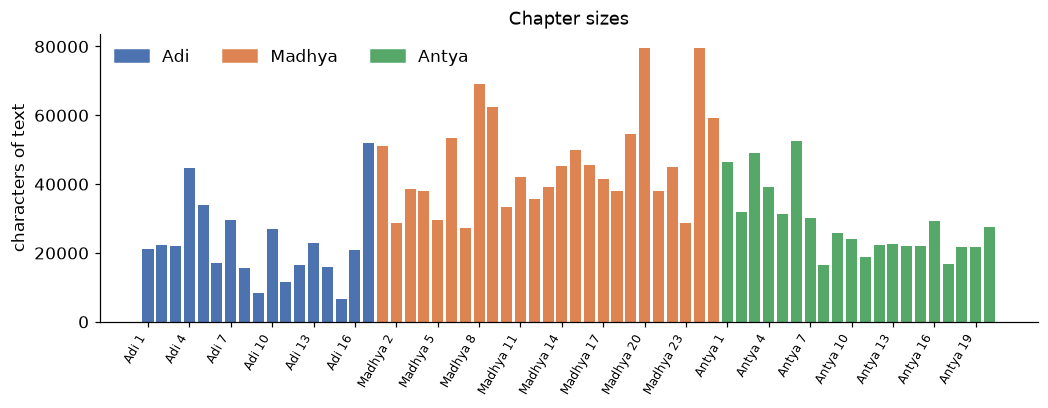

In [4]:
# Chapter sizes, to show the unit of analysis is reasonably even.
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(len(records)), [len(r['text']) for r in records],
       color=[LILA_COLOURS[r['lila']] for r in records])
ax.set_xticks(range(0, len(records), 3))
ax.set_xticklabels([labels[i] for i in range(0, len(labels), 3)],
                   rotation=60, ha='right', fontsize=8)
ax.set_ylabel('characters of text')
ax.set_title('Chapter sizes')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in LILA_COLOURS.values()]
ax.legend(handles, LILA_COLOURS.keys(), frameon=False, ncol=3)
fig.savefig(os.path.join(FIGURES, 'fig0_chapter_sizes.png'))
plt.show()

## 1b. Corpus excerpt

A sample of the extracted text, after legacy-font repair. The source PDFs use
the Balaram font, so raw extraction yields `Kaa` for `Krsna` and `Cre` for
`Sri`; everything below has been mapped back to IAST.

In [5]:
sample = records[12]
para = [p for p in sample['text'].split('\n\n') if len(p) > 220][1]
print(f"--- {sample['label']} ---\n")
import textwrap
print(textwrap.fill(para[:700], 88))

--- Adi 13 ---

When teaching a course in grammar [vyākaraṇa] and explaining it with notes, Śrī Caitanya
Mahāprabhu taught His disciples about the glories of Lord Kṛṣṇa. All explanations
culminated in Kṛṣṇa, and His disciples would understand them very easily. Thus His
influence was wonderful.


## 2. Character identification

spaCy's entity **labels** are unreliable here - it tags `Caitanya` as a place
and splits `Krsna` between PERSON and ORG - so candidates are pooled across
labels and resolved by name in `characters.py`: honorific stripping, an alias
map, a 190-entry non-character stoplist, and a table of protected names whose
final word disambiguates rather than decorates (`Ramacandra Puri` vs
`Ramacandra Khan`).

Filter: **>=10 mentions, then the top 50%.** The Ramcharitmanas study used
the top 30%; at that setting the cutoff here falls at 38 mentions and drops
`Ramacandra Khan` (24 mentions), the figure who plots against Haridasa and the
clearest human antagonist in Antya-lila. A filter that discards a named
antagonist is measuring prominence rather than narrative role.

In [6]:
cache = os.path.join(narrative.RESULTS, 'characters_cache.json')
if USE_CACHE and os.path.exists(cache):
    with open(cache, encoding='utf-8') as fh:
        blob = json.load(fh)
    mentions, surface = Counter(blob['mentions']), blob['surface']
else:
    nlp = common.load_spacy()
    mentions, surface = narrative.find_characters(
        nlp, [r['text'] for r in records])
    with open(cache, 'w', encoding='utf-8') as fh:
        json.dump({'mentions': dict(mentions), 'surface': surface},
                  fh, ensure_ascii=False)

cast, eligible = narrative.select_cast(mentions)
index = narrative.mention_index(cast, surface)
print(f'{len(eligible)} characters with >=10 mentions; cast of {len(cast)}')
display(pd.DataFrame(eligible[:20], columns=['Character', 'Mentions'])
          .style.hide(axis='index'))

145 characters with >=10 mentions; cast of 72


Character,Mentions
Caitanya,5588
Kṛṣṇa,2835
Jagannātha,708
Nityānanda,480
Advaita,404
Sanātana,403
Svarūpa Dāmodara,327
Raghunātha,304
Haridāsa,299
Rādhārāṇī,284


## 3. Character interaction network

Nodes are characters; edge weight counts the sentences naming both
(sentence-level co-occurrence, after Das, Das & Mahesh 2016).

Matching is **longest-match-first**: a sentence naming `Ramacandra Puri` must
not also register bare `Ramacandra`, which would create a phantom edge between
two different people.

In [7]:
G = narrative.build_interaction_network(records, index)
metrics = narrative.network_metrics(G)
print(f"nodes {metrics['nodes']}, edges {metrics['edges']}, "
      f"density {metrics['density']:.3f}, "
      f"{len(metrics['communities'])} communities, "
      f"clustering {metrics['clustering']:.3f} "
      f"(weighted {metrics['clustering_weighted']:.3f}, "
      f"uninformative here -- see narrative.network_metrics)")

nodes 72, edges 778, density 0.304, 5 communities, clustering 0.712 (weighted 0.010, uninformative here -- see narrative.network_metrics)


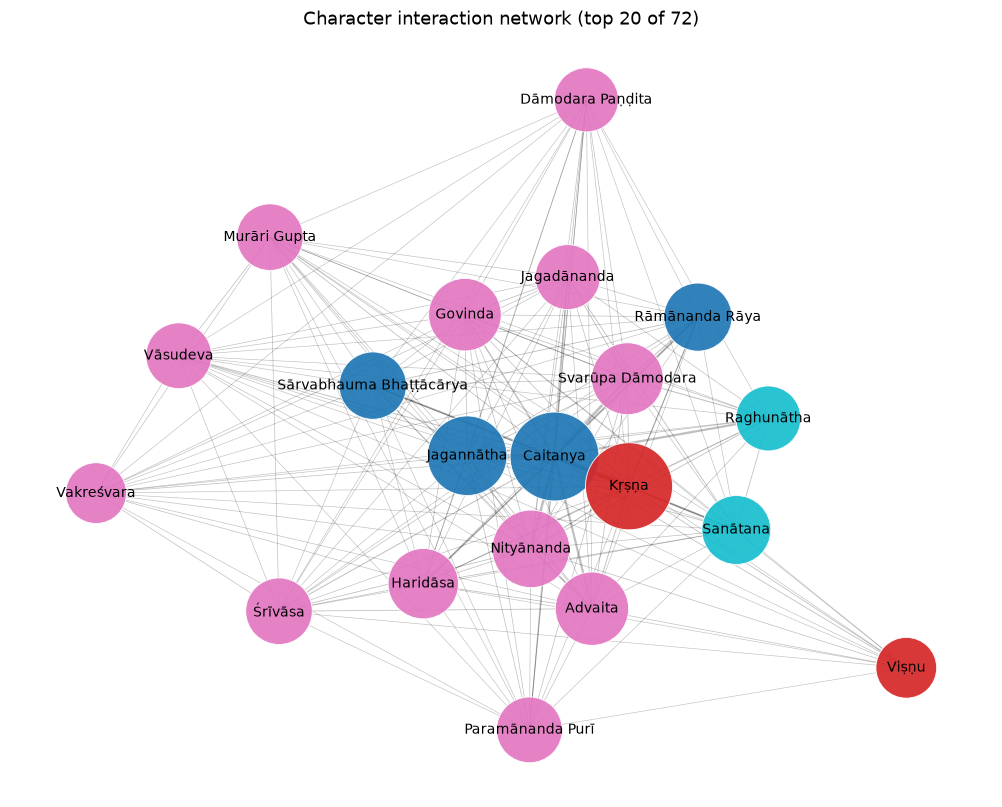

In [8]:
# FIGURE 1 - the network, top 20 by degree, coloured by community.
TOP = 20
degree = metrics['degree']
keep = sorted(degree, key=degree.get, reverse=True)[:TOP]
H = G.subgraph(keep)
pos = nx.spring_layout(H, seed=1, weight='weight', k=0.75)
wmax = max(d['weight'] for *_, d in H.edges(data=True))

fig, ax = plt.subplots(figsize=(11.5, 9))
nx.draw_networkx_edges(
    H, pos, ax=ax, alpha=0.25,
    width=[0.4 + 3.0 * (H[u][v]['weight'] / wmax) for u, v in H.edges()])
nx.draw_networkx_nodes(
    H, pos, ax=ax,
    node_size=[3200 * degree[n] + 320 for n in H],
    node_color=[metrics['membership'][n] for n in H],
    cmap='tab10', alpha=0.92, linewidths=0.6, edgecolors='white')
nx.draw_networkx_labels(H, pos, ax=ax, font_size=9)
ax.set_title(f"Character interaction network (top {TOP} of {metrics['nodes']})")
ax.axis('off')
fig.savefig(os.path.join(FIGURES, 'fig1_character_network.png'))
plt.show()

In [9]:
# TABLE - centrality. Degree/betweenness vs eigenvector is the key contrast.
def top(metric, n=10):
    return sorted(metrics[metric].items(), key=lambda kv: kv[1],
                  reverse=True)[:n]

cent = pd.DataFrame({
    'Degree': [c for c, _ in top('degree')],
    'deg': [round(v, 3) for _, v in top('degree')],
    'Betweenness': [c for c, _ in top('betweenness')],
    'btw': [round(v, 3) for _, v in top('betweenness')],
    'Eigenvector': [c for c, _ in top('eigenvector')],
    'eig': [round(v, 3) for _, v in top('eigenvector')],
})
display(cent.style.hide(axis='index'))

Degree,deg,Betweenness,btw,Eigenvector,eig
Caitanya,0.958000,Caitanya,0.156000,Caitanya,0.647000
Kṛṣṇa,0.915000,Kṛṣṇa,0.143000,Kṛṣṇa,0.427000
Jagannātha,0.746000,Jagannātha,0.056000,Jagannātha,0.306000
Nityānanda,0.704000,Nityānanda,0.049000,Nityānanda,0.207000
Advaita,0.620000,Advaita,0.027000,Rūpa,0.188000
Govinda,0.606000,Govinda,0.025000,Raghunātha,0.174000
Svarūpa Dāmodara,0.592000,Svarūpa Dāmodara,0.022000,Advaita,0.170000
Haridāsa,0.563000,Haridāsa,0.020000,Rāmānanda Rāya,0.159000
Sanātana,0.535000,Sanātana,0.018000,Sanātana,0.157000
Rāmānanda Rāya,0.521000,Raghunātha,0.018000,Svarūpa Dāmodara,0.154000


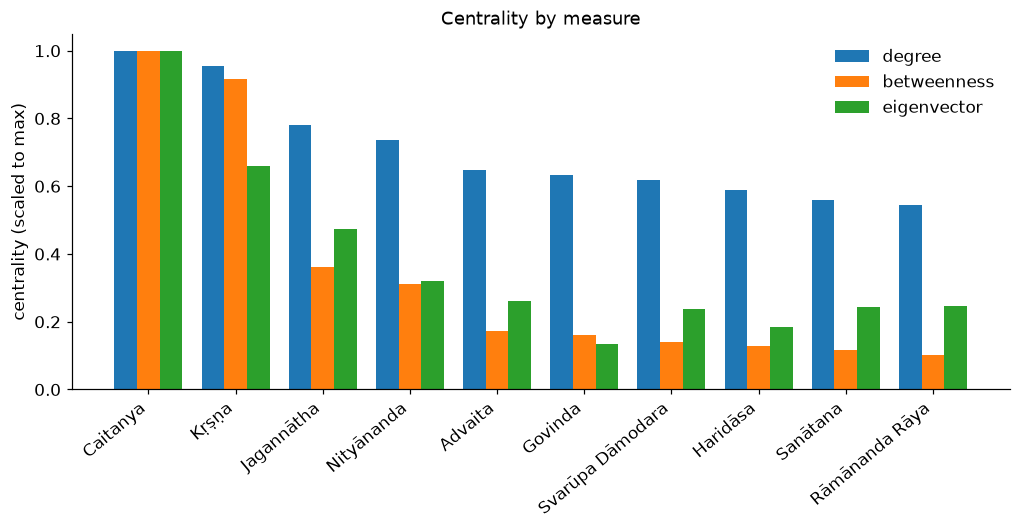

In [10]:
# FIGURE 2 - the same contrast as a chart, scaled per measure.
chars = [c for c, _ in top('degree', 10)]
measures = ['degree', 'betweenness', 'eigenvector']
fig, ax = plt.subplots(figsize=(11, 4.2))
width = 0.26
for i, m in enumerate(measures):
    mx = max(metrics[m].values()) or 1
    ax.bar([x + i * width for x in range(len(chars))],
           [metrics[m].get(c, 0) / mx for c in chars],
           width=width, label=m)
ax.set_xticks([x + width for x in range(len(chars))])
ax.set_xticklabels(chars, rotation=40, ha='right')
ax.set_ylabel('centrality (scaled to max)')
ax.set_title('Centrality by measure')
ax.legend(frameon=False)
fig.savefig(os.path.join(FIGURES, 'fig2_centrality.png'))
plt.show()

In [11]:
# TABLE - communities. These recover the phases of Caitanya's life.
rows = [{'Community': i, 'Size': len(g), 'Members': ', '.join(g)}
        for i, g in enumerate(metrics['communities'])]
display(pd.DataFrame(rows).sort_values('Size', ascending=False)
          .style.hide(axis='index'))

Community,Size,Members
2,21,"Advaita, Brahmānanda Bhāratī, Dāmodara Paṇḍita, Gadādhara, Gadādhara Paṇḍita, Govinda, Haridāsa, Jagadānanda, Kāśīśvara, Mukunda, Murāri Gupta, Nityānanda, Paramānanda Purī, Rāghava, Rāmacandra Khān, Rāmadāsa, Saṅkarṣaṇa, Svarūpa Dāmodara, Vakreśvara, Vāsudeva, Śrīvāsa"
0,20,"Balabhadra Bhaṭṭācārya, Bhavānanda Rāya, Caitanya, Gopīnātha Paṭṭanāyaka, Gopīnātha Ācārya, Jagannātha, Jagannātha Miśra, Kazi, Kālidāsa, Kāśī Miśra, Mukunda Datta, Pradyumna Miśra, Prakāśānanda Sarasvatī, Pratāparudra, Puruṣottama, Rāmānanda Rāya, Sārvabhauma Bhaṭṭācārya, Vallabha, Śacīdevī, Śivānanda Sena"
1,16,"Brahmā, Cupid, Indra, Kali, Kṛṣṇa, Mahā-Viṣṇu, Nanda, Nārada Muni, Nārāyaṇa, Rādhā, Rādhārāṇī, Viṣṇu, Vyāsadeva, Yaśodā, Śiva, Śukadeva"
3,8,"Advaitacandra, Candraśekhara, Jīva, Kṛṣṇadāsa, Raghunātha, Rūpa, Sanātana, Tapana Miśra"
4,7,"Gopāla, Gopīnātha, Mādhavendra Purī, Rāmacandra, Rāmacandra Purī, Sītā, Īśvara Purī"


## 3b. Networks per lila

The Ramcharitmanas study built a top-20 character network for each of its seven
kandas. The CC's structural equivalent is the three lilas, so the same view is
given per lila here. This is what shows the cast turning over as the narrative
moves from Navadvipa to Puri to Vrndavana.

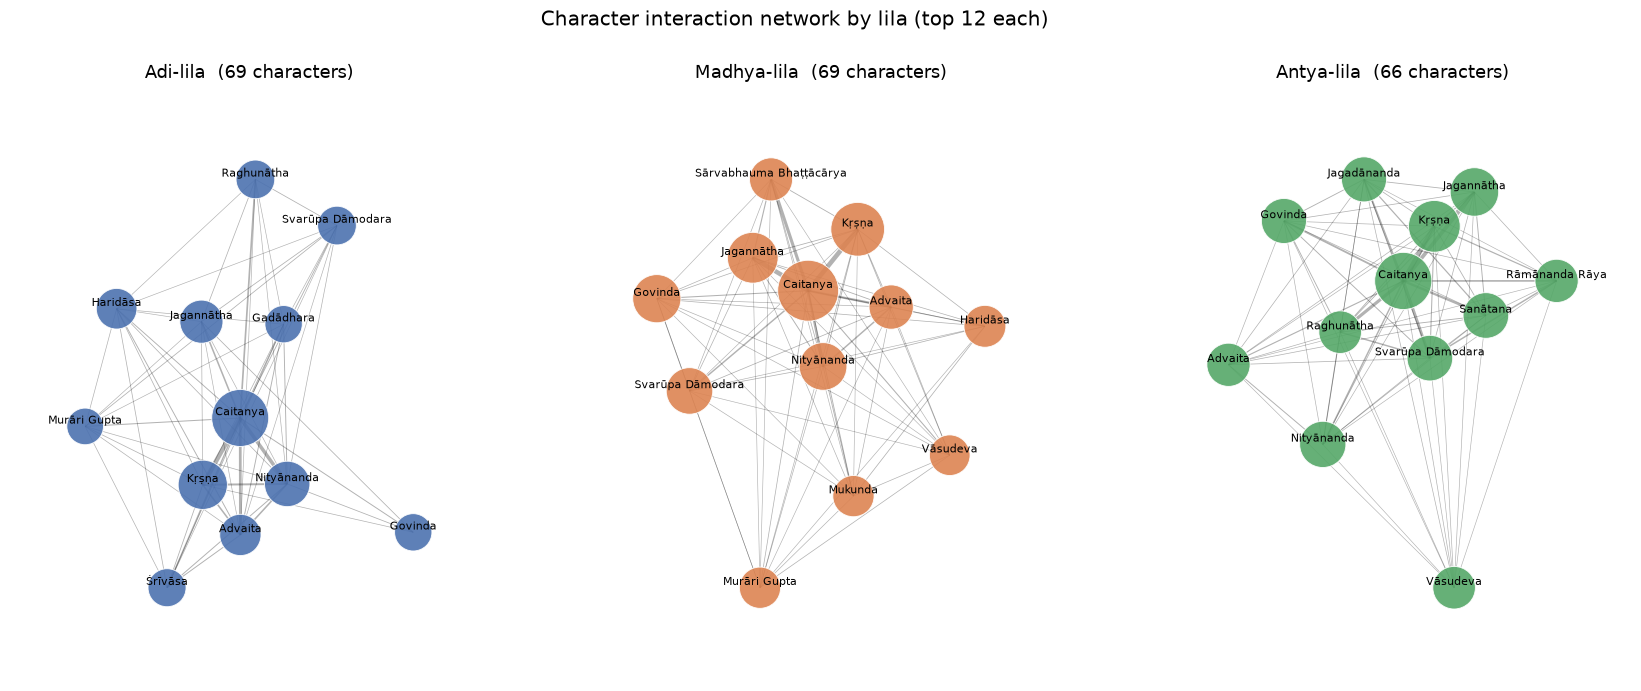

Lila,Nodes,Edges,Density,Communities,Top by degree
Adi,69,356,0.152000,8,"Caitanya, Kṛṣṇa, Nityānanda, Jagannātha"
Madhya,69,514,0.219000,7,"Caitanya, Kṛṣṇa, Jagannātha, Govinda"
Antya,66,425,0.198000,6,"Caitanya, Kṛṣṇa, Jagannātha, Nityānanda"


In [12]:
# FIGURE 1b - one network per lila, top 12 each for legibility.
fig, axes = plt.subplots(1, 3, figsize=(19, 7))
per_lila_stats = []

for ax, lila in zip(axes, narrative.LILA_ORDER):
    subset = [r for r in records if r['lila'] == lila]
    Gl = narrative.build_interaction_network(subset, index)
    if Gl.number_of_edges() == 0:
        ax.axis('off')
        continue
    ml = narrative.network_metrics(Gl)
    per_lila_stats.append({
        'Lila': lila, 'Nodes': ml['nodes'], 'Edges': ml['edges'],
        'Density': round(ml['density'], 3),
        'Communities': len(ml['communities']),
        'Top by degree': ', '.join(
            c for c, _ in sorted(ml['degree'].items(),
                                 key=lambda kv: kv[1], reverse=True)[:4]),
    })
    deg = ml['degree']
    keep_l = sorted(deg, key=deg.get, reverse=True)[:12]
    Hl = Gl.subgraph(keep_l)
    posl = nx.spring_layout(Hl, seed=2, weight='weight', k=2.2)
    wl = max(d['weight'] for *_, d in Hl.edges(data=True))
    nx.draw_networkx_edges(
        Hl, posl, ax=ax, alpha=0.3,
        width=[0.4 + 2.6 * (Hl[u][v]['weight'] / wl) for u, v in Hl.edges()])
    nx.draw_networkx_nodes(
        Hl, posl, ax=ax,
        node_size=[1500 * deg[n] + 200 for n in Hl],
        node_color=LILA_COLOURS[lila], alpha=0.9,
        linewidths=0.6, edgecolors='white')
    nx.draw_networkx_labels(Hl, posl, ax=ax, font_size=7.5,
                        verticalalignment='bottom')
    ax.margins(0.16)
    ax.set_title(f'{lila}-lila  ({ml["nodes"]} characters)')
    ax.axis('off')

fig.suptitle('Character interaction network by lila (top 12 each)')
fig.savefig(os.path.join(FIGURES, 'fig1b_networks_by_lila.png'))
plt.show()

display(pd.DataFrame(per_lila_stats).style.hide(axis='index'))

## 4. Sentiment across chapters

VADER compound sentiment, averaged over the sentences naming each character,
chapter by chapter.

**Caveat for the paper.** VADER is scoped to social-media text (Hutto & Gilbert
2014). Rebora (2023, *DHQ*) shows it performs poorly on literary prose, and
Sprugnoli et al. (2016) found human annotators cannot reach acceptable
agreement on sentiment in historical texts. Treat these curves as a screening
signal needing manual confirmation, not as measurement.

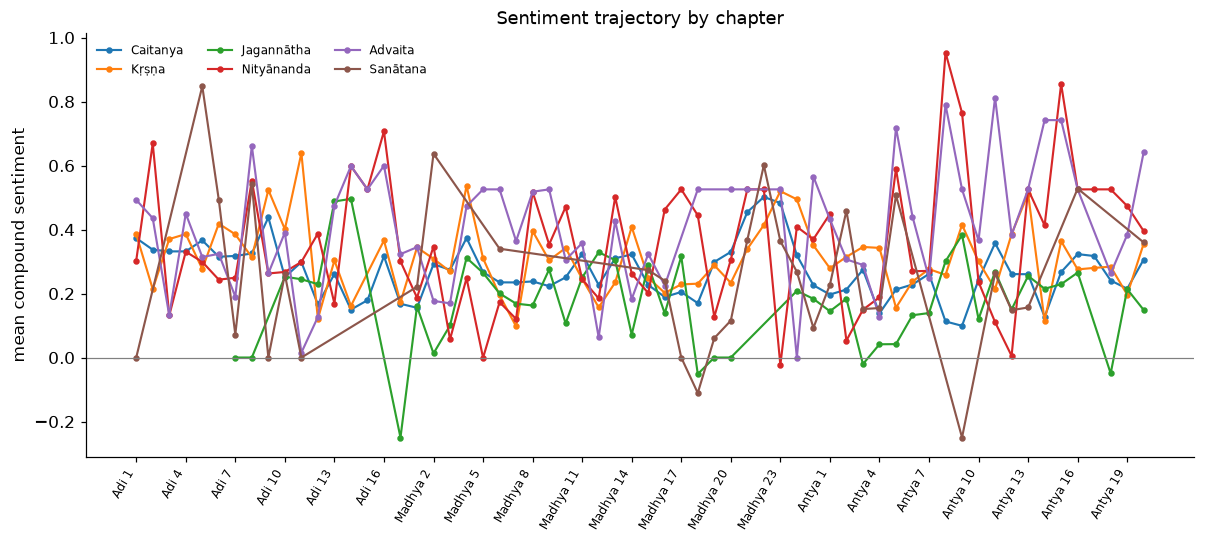

In [13]:
traj = narrative.sentiment_trajectories(records, index, analyzer, cast)

# FIGURE 3 - trajectories for the leads.
fig, ax = plt.subplots(figsize=(13, 5))
for c in cast[:6]:
    xs = [i for i, v in enumerate(traj[c]) if v is not None]
    ys = [v for v in traj[c] if v is not None]
    if xs:
        ax.plot(xs, ys, marker='o', ms=3.2, linewidth=1.4, label=c)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xticks(range(0, len(labels), 3))
ax.set_xticklabels([labels[i] for i in range(0, len(labels), 3)],
                   rotation=60, ha='right', fontsize=8)
ax.set_ylabel('mean compound sentiment')
ax.set_title('Sentiment trajectory by chapter')
ax.legend(fontsize=8, frameon=False, ncol=3)
fig.savefig(os.path.join(FIGURES, 'fig3_sentiment_trends.png'))
plt.show()

In [14]:
# TABLE - most negatively contextualised characters.
means = {c: statistics.fmean([v for v in vs if v is not None])
         for c, vs in traj.items() if any(v is not None for v in vs)}
neg = pd.DataFrame(
    [(c, round(m, 4), sum(1 for v in traj[c] if v is not None))
     for c, m in sorted(means.items(), key=lambda kv: kv[1])[:10]],
    columns=['Character', 'Mean compound', 'Chapters present'])
display(neg.style.hide(axis='index'))

Character,Mean compound,Chapters present
Rāmacandra Purī,-0.312100,5
Rāmacandra Khān,-0.150300,2
Gopīnātha Paṭṭanāyaka,-0.094700,4
Indra,0.057300,16
Pratāparudra,0.073700,13
Jagannātha Miśra,0.079000,9
Brahmānanda Bhāratī,0.095100,13
Viṣṇu,0.096300,39
Gopīnātha,0.121800,14
Kazi,0.128700,3


## 5. Emotion profiles

NRC emotion lexicon, as a share of each character's emotion-bearing words.

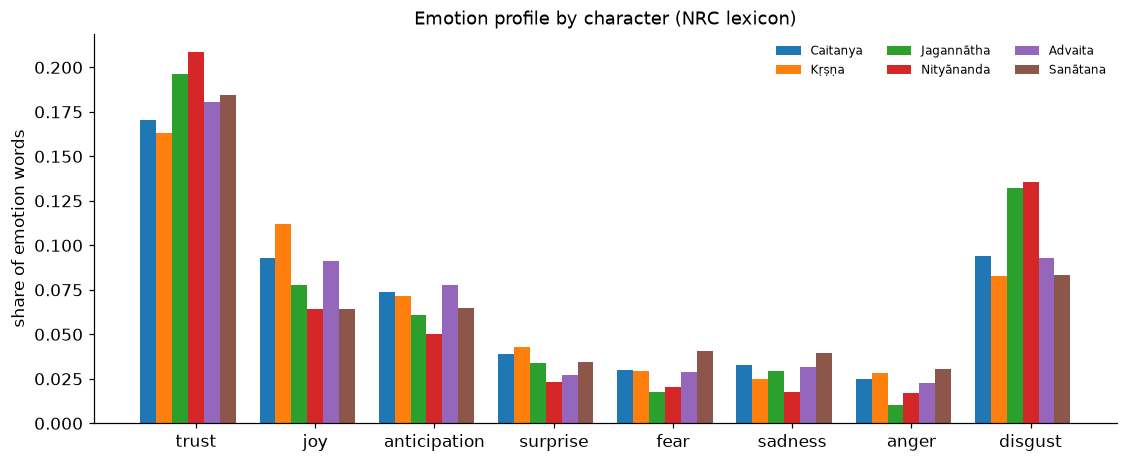

,trust,joy,anticipation,surprise,fear,sadness,anger,disgust
Caitanya,0.1704,0.0928,0.0738,0.0387,0.0301,0.0325,0.0249,0.0939
Kṛṣṇa,0.1629,0.1119,0.0717,0.0426,0.0295,0.0251,0.0282,0.0828
Jagannātha,0.1961,0.0779,0.0608,0.0336,0.0178,0.0296,0.0105,0.1321
Nityānanda,0.2085,0.0644,0.0503,0.0234,0.0205,0.0173,0.0170,0.1358
Advaita,0.1807,0.0909,0.0778,0.0274,0.0286,0.0314,0.0229,0.0926
Sanātana,0.1842,0.0644,0.0650,0.0347,0.0404,0.0397,0.0303,0.0833


In [15]:
profiles, bucket = narrative.emotion_profiles(records, index, cast, STOP)

# FIGURE 4 - Plutchik's eight, excluding the positive/negative aggregates.
emotions = ['trust', 'joy', 'anticipation', 'surprise',
            'fear', 'sadness', 'anger', 'disgust']
names = cast[:6]
fig, ax = plt.subplots(figsize=(12, 4.6))
width = 0.8 / len(names)
for i, name in enumerate(names):
    ax.bar([x + i * width for x in range(len(emotions))],
           [profiles.get(name, {}).get(e, 0) for e in emotions],
           width=width, label=name)
ax.set_xticks([x + 0.4 for x in range(len(emotions))])
ax.set_xticklabels(emotions)
ax.set_ylabel('share of emotion words')
ax.set_title('Emotion profile by character (NRC lexicon)')
ax.legend(fontsize=8, frameon=False, ncol=3)
fig.savefig(os.path.join(FIGURES, 'fig4_emotions.png'))
plt.show()

display(pd.DataFrame({n: {e: profiles.get(n, {}).get(e, 0) for e in emotions}
                      for n in names}).T.round(4))

## 6. Narrative presence

How often each lead is named, chapter by chapter - the analogue of the
Ramcharitmanas study's narrative-analysis graph.

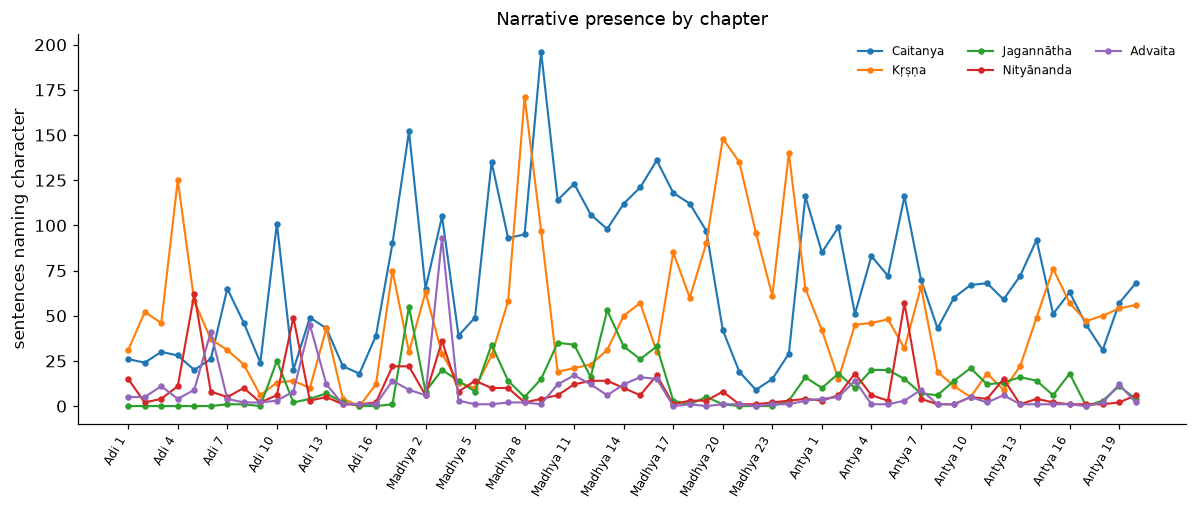

In [16]:
# FIGURE 5
fig, ax = plt.subplots(figsize=(13, 4.6))
for c in cast[:5]:
    counts = [sum(1 for s in r['sentences']
                  if c in narrative.characters_in(s, index)) for r in records]
    ax.plot(range(len(counts)), counts, marker='o', ms=3.2,
            linewidth=1.4, label=c)
ax.set_xticks(range(0, len(labels), 3))
ax.set_xticklabels([labels[i] for i in range(0, len(labels), 3)],
                   rotation=60, ha='right', fontsize=8)
ax.set_ylabel('sentences naming character')
ax.set_title('Narrative presence by chapter')
ax.legend(fontsize=8, frameon=False, ncol=3)
fig.savefig(os.path.join(FIGURES, 'fig5_narrative_presence.png'))
plt.show()

## 7. Word clouds

Vocabulary surrounding each lead character.

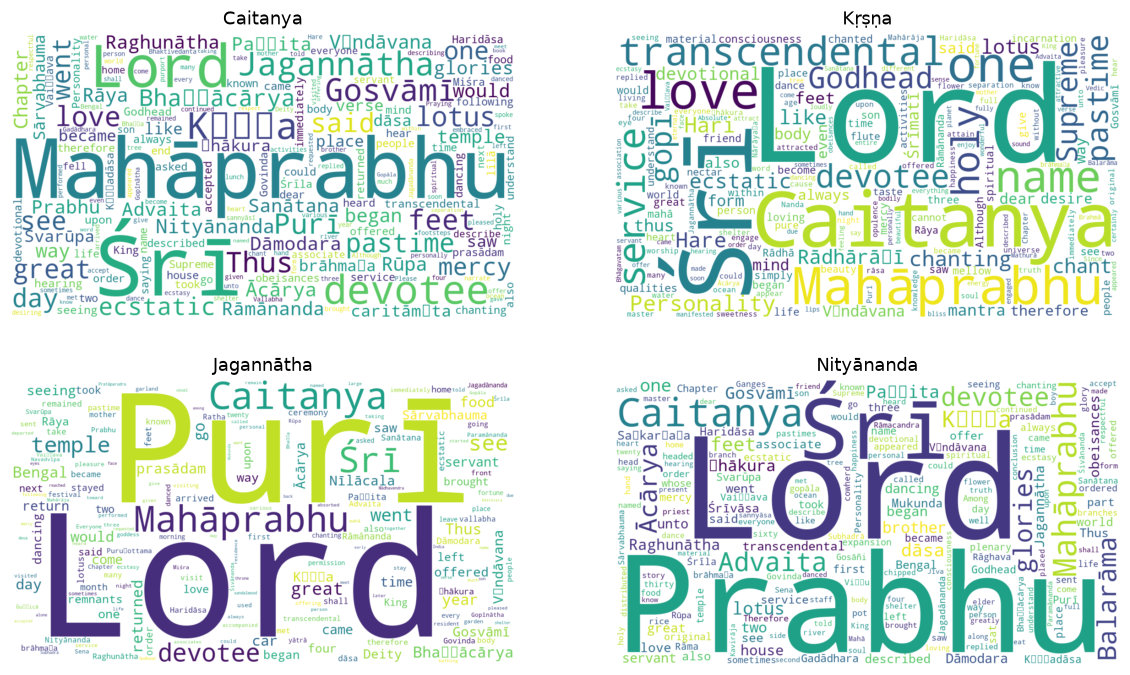

In [17]:
from wordcloud import WordCloud

leads = cast[:4]
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, name in zip(axes.ravel(), leads):
    cloud = WordCloud(width=1100, height=620, background_color='white',
                      stopwords=STOP | {name.lower()},
                      collocations=False).generate(' '.join(bucket[name]))
    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(name)
    ax.axis('off')
    cloud.to_file(os.path.join(
        FIGURES, 'fig6_wordcloud_' + name.replace(' ', '_') + '.png'))
fig.savefig(os.path.join(FIGURES, 'fig6_wordclouds.png'))
plt.show()

## 8. Topic model

Latent Dirichlet Allocation over the 62 chapters, 5 topics.

In [18]:
topics = narrative.topic_model([r['text'] for r in records], STOP)
display(pd.DataFrame(
    [(f'Topic {i+1}', ', '.join(t)) for i, t in enumerate(topics)],
    columns=['Topic', 'Top terms']).style.hide(axis='index'))

Topic,Top terms
Topic 1,"purī, devotional, brāhmaṇa, mādhavendra, deity, gopāla, devotee, offered, material, word, rāmacandra, temple"
Topic 2,"material, spiritual, sanātana, viṣṇu, gosvāmī, form, living, energy, incarnations, called, original, devotional"
Topic 3,"jagannātha, rāmānanda, began, ecstatic, rāya, bhaṭṭācārya, gopīs, dāmodara, vṛndāvana, svarūpa, sārvabhauma, rādhārāṇī"
Topic 4,"gosvāmī, dāsa, paṇḍita, haridāsa, jagannātha, purī, sanātana, prabhu, vṛndāvana, dāmodara, jagadānanda, śrīla"
Topic 5,"miśra, brāhmaṇa, came, jagannātha, mother, spiritual, form, bhaṭṭācārya, began, went, devotional, immediately"


## 9. Word frequencies by lila

Which vocabulary distinguishes each of the three sections.

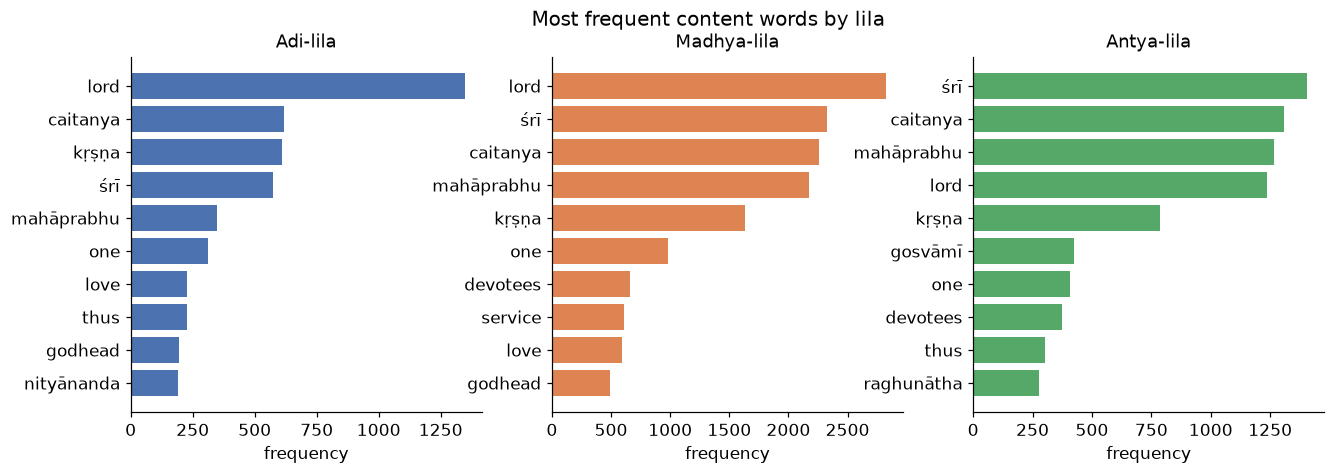

In [19]:
freq = {l: narrative.word_frequencies(
            '\n'.join(r['text'] for r in records if r['lila'] == l), STOP, 10)
        for l in narrative.LILA_ORDER}

# FIGURE 7
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (lila, items) in zip(axes, freq.items()):
    ws = [w for w, _ in items][::-1]
    ns = [n for _, n in items][::-1]
    ax.barh(ws, ns, color=LILA_COLOURS[lila])
    ax.set_title(f'{lila}-lila')
    ax.set_xlabel('frequency')
fig.suptitle('Most frequent content words by lila')
fig.savefig(os.path.join(FIGURES, 'fig7_word_frequencies.png'))
plt.show()

## 10. Export and limitations

Figures are in `results/figures/` at 300 dpi. Full numeric results, including
per-chapter sentiment for every cast member, come from `python narrative.py`
into `results/narrative.json`.

### Limitations to state in the paper

1. **Lexical resolution, not coreference.** Pronouns (`He`, `the Lord`) are not
   attributed, so mention counts are lower bounds.
2. **Sentiment tooling is out of domain** (see section 4).
3. **The corpus is a translation.** Graph measures are known to differ between
   original-language and translated versions, so conclusions concern this
   English edition.
4. **The cast filter was raised from the top 30% to the top 50%** so that
   `Ramacandra Khan` (24 mentions) is included; at 30% the cutoff was 38 and
   dropped him. This is a deliberate departure from the Ramcharitmanas study's
   setting and should be stated as such.